# Análisis de tráfico — Cartagena

Datos de la base local `trafico` (tabla `mediciones`): 113 nodos consultados en TomTom Traffic Flow.

**Ojo:** TomTom no mide el punto exacto sino el **tramo de vía completo** donde cae cada nodo. Varios nodos pueden caer en el mismo tramo, y un tramo largo acumula más segundos de demora aunque no esté más congestionado. Por eso el ranking se ordena por **% de demora relativa**, no por segundos.

**Métricas usadas**
- **% demora relativa:** `delay_rel_pct`, cuánto más tarda el tramo frente a la vía libre. 50 % = tarda 1,5 veces lo normal.
- **Demora (seg):** `delay_abs_seg`, segundos extra en todo el tramo; depende de lo largo que sea.
- **Índice de congestión:** `1 - velocidad_ratio`. 0 = va a velocidad libre; 0,5 = va a la mitad.
- **% congestionado:** porcentaje de mediciones con velocidad < 70 % de la libre.

Para actualizar los datos, recarga el backup en la base `trafico` y vuelve a ejecutar todo (**Run → Run All Cells**).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

UMBRAL_CONGESTION = 0.7   # velocidad actual < 70 % de la libre
CONFIANZA_MIN = 0.7       # descarta mediciones poco confiables de TomTom

df = pd.read_sql(
    """select id_nodo, nombre_nodo, consultation_time, dia_semana,
              "currentSpeed", "freeFlowSpeed", delay_abs_seg, delay_rel_pct, velocidad_ratio, "freeFlowTravelTime", confidence, "roadClosure"
       from mediciones
       where ok and consultation_time is not null""",
    "postgresql:///trafico",
)
df = df[df["confidence"] >= CONFIANZA_MIN].copy()
df["hora"] = df["consultation_time"].dt.hour
df["congestion"] = 1 - df["velocidad_ratio"]
df["congestionado"] = df["velocidad_ratio"] < UMBRAL_CONGESTION

DIAS = ["Lunes", "Martes", "Miercoles", "Jueves", "Viernes", "Sabado", "Domingo"]
df["dia_semana"] = pd.Categorical(df["dia_semana"], categories=DIAS, ordered=True)

print(f"Mediciones: {len(df):,}")
print(f"Nodos: {df['id_nodo'].nunique()}")
print(f"Periodo: {df['consultation_time'].min():%d/%m/%Y} a {df['consultation_time'].max():%d/%m/%Y} "
      f"({df['consultation_time'].dt.date.nunique()} días)")

Mediciones: 359,664
Nodos: 113
Periodo: 30/05/2026 a 30/09/2026 (124 días)


## 1. Ranking de puntos críticos (todo el día)

Ordenado por % de demora relativa. `duracion_tramo_seg` es lo que tarda el tramo a vía libre: sirve para ver si la demora en segundos viene de un tramo largo.

In [2]:
ranking = (
    df.groupby("nombre_nodo")
      .agg(demora_rel_pct=("delay_rel_pct", "mean"),
           demora_prom_seg=("delay_abs_seg", "mean"),
           demora_p90_seg=("delay_abs_seg", lambda s: s.quantile(0.9)),
           pct_congestionado=("congestionado", "mean"),
           vel_actual_prom=("currentSpeed", "mean"),
           vel_libre_prom=("freeFlowSpeed", "mean"),
           duracion_tramo_seg=("freeFlowTravelTime", "median"),
           mediciones=("delay_abs_seg", "size"))
      .sort_values("demora_rel_pct", ascending=False)
)
ranking["pct_congestionado"] *= 100

top = ranking.head(15)
top.style.format({"demora_rel_pct": "{:.1f} %", "duracion_tramo_seg": "{:.0f}", "demora_prom_seg": "{:.0f}", "demora_p90_seg": "{:.0f}",
                  "pct_congestionado": "{:.1f} %", "vel_actual_prom": "{:.0f}",
                  "vel_libre_prom": "{:.0f}", "mediciones": "{:,}"}) \
   .background_gradient(subset=["demora_rel_pct", "pct_congestionado"], cmap="Reds")

,demora_rel_pct,demora_prom_seg,demora_p90_seg,pct_congestionado,vel_actual_prom,vel_libre_prom,duracion_tramo_seg,mediciones
nombre_nodo,,,,,,,,
Parque pie de la popa Leones,61.0 %,43,100,57.0 %,24,34,70,"3,184"
La India Catalina,55.3 %,41,92,55.0 %,26,36,74,"3,184"
Rotonda El Prado,50.1 %,19,50,42.9 %,18,24,37,"3,184"
Tienda La Niña Salomé,46.8 %,286,549,54.5 %,26,36,612,"3,184"
KFC-Bomba del amparo,46.7 %,286,549,54.6 %,26,36,612,"3,184"
Calle 26 C - Junin,46.7 %,286,549,54.6 %,26,36,612,"3,184"
Bazurto,46.7 %,286,549,54.6 %,26,36,612,"3,184"
Mueble jamar - Cuatro Viento,40.4 %,279,509,51.9 %,29,40,689,"3,184"
Ferreteria La Esquina Del Color,40.3 %,279,509,51.9 %,29,40,689,"3,184"


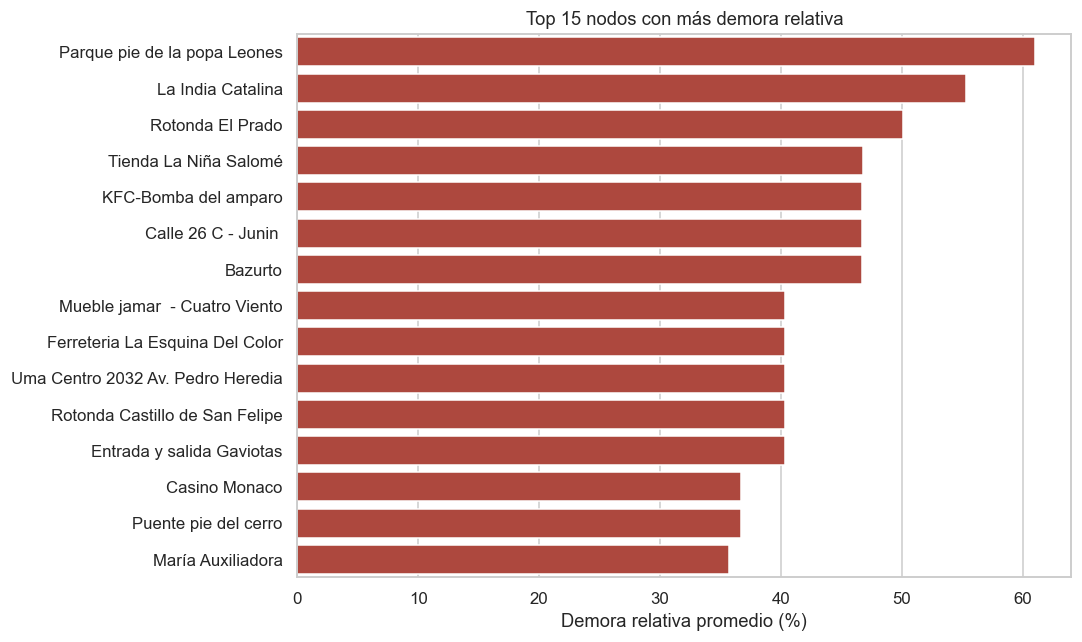

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=top.reset_index(), y="nombre_nodo", x="demora_rel_pct", color="#c0392b", ax=ax)
ax.set(title="Top 15 nodos con más demora relativa", xlabel="Demora relativa promedio (%)", ylabel="")
plt.tight_layout(); plt.show()

## 1b. Nodos que comparten el mismo tramo

Nodos con la misma duración de tramo y la misma demora promedio: TomTom les devuelve el mismo tramo de vía, así que en la práctica miden lo mismo. Consultar solo uno por grupo ahorra créditos.

In [4]:
firma = ranking.assign(_d=ranking["demora_prom_seg"].round(0), _t=ranking["duracion_tramo_seg"].round(0))
tramos = (firma.reset_index().groupby(["_t", "_d"])
          .agg(nodos=("nombre_nodo", list), n=("nombre_nodo", "size"),
               demora_rel_pct=("demora_rel_pct", "mean"))
          .query("n > 1").sort_values("n", ascending=False).reset_index(drop=True))
tramos["nodos"] = tramos["nodos"].str.join(", ")
print(f"{int(tramos['n'].sum())} nodos caen en {len(tramos)} tramos compartidos "
      f"→ {int(tramos['n'].sum() - len(tramos))} consultas redundantes por corrida")
tramos.style.format({"demora_rel_pct": "{:.1f} %"})

84 nodos caen en 29 tramos compartidos → 55 consultas redundantes por corrida


,nodos,n,demora_rel_pct
0,"CDA SUPERCARS La termianal, Salida de Bicentenario, La Gran Bodega De La Construcción, Restaurante chino. EL BONSÁI CTG, Entrada Pozón Ara, Rotonda Pozón - Avenida Pedro Romero, Motel Villa Campestre, Casa Cecilia los Alpes - Bomba del gallo/13junio",8,19.0 %
1,"Semaforo al mall plaza, Y Calle 54 Santa Rita, JA Carnes San Francisco, Western Union - Paseo Bolivar, Caí Santa Rita, Puesto De Salud Islote San Bernardo",6,23.6 %
2,"Mueble jamar - Cuatro Viento, Ferreteria La Esquina Del Color, Uma Centro 2032 Av. Pedro Heredia, Rotonda Castillo de San Felipe, Entrada y salida Gaviotas",5,40.3 %
3,"Éxito de la matuna, Castillogrande Carrera 14a, AGEM ADUANA SAS, Laboratorio de Rey, Tienda y Terraza el Nuevo Trébol",5,27.2 %
4,"Tienda La Niña Salomé, KFC-Bomba del amparo, Calle 26 C - Junin , Bazurto",4,46.7 %
5,"Castellana parte de atrás, Tienda El Paisa, Integral Design CM, Parque Piedra Bolivar",4,24.3 %
6,"Letras Vía Perimetral, Inicio de via perimetral, Vía Perimetral Kra 41, Zambi Zona de Aprendizaje Múltiple y Bienestar",4,2.2 %
7,"CAI de ceballos, Carretera Vía Mamonal - Cootrasur , Campestre",3,23.9 %
8,"Rotonda Bicentenario, Parque Heredia - Sala de Ventas Amarilo, Colegio Nuestra Señora de Fatima - Ternera",3,31.6 %
9,"Entrada Terminal de Transporte, Rotonda La Gran Manzana, Y de Olaya",3,17.0 %


## 2. Ranking por franja pico (% de demora relativa)

In [5]:
FRANJAS = {"Mañana (6–8 h)": range(6, 9),
           "Mediodía (12–13 h)": range(12, 14),
           "Tarde (17–19 h)": range(17, 20)}

tablas = {}
for nombre, horas in FRANJAS.items():
    tablas[nombre] = (df[df["hora"].isin(horas)]
                      .groupby("nombre_nodo")["delay_rel_pct"].mean()
                      .sort_values(ascending=False).head(10).round(0))

pd.DataFrame({k: [f"{n} ({v:.0f} %)" for n, v in t.items()] for k, t in tablas.items()},
             index=range(1, 11))

,Mañana (6–8 h),Mediodía (12–13 h),Tarde (17–19 h)
1,Parque pie de la popa Leones (68 %),Parque pie de la popa Leones (94 %),La India Catalina (111 %)
2,Restaurante Nuevo Asia (60 %),Rotonda El Prado (77 %),Tienda La Niña Salomé (77 %)
3,El Bodegon de San Isidro (60 %),Tienda La Niña Salomé (73 %),Bazurto (77 %)
4,María Auxiliadora (55 %),Bazurto (73 %),KFC-Bomba del amparo (77 %)
5,Rotonda El Prado (55 %),KFC-Bomba del amparo (73 %),Calle 26 C - Junin (77 %)
6,Mueble jamar - Cuatro Viento (48 %),Calle 26 C - Junin (73 %),Casino Monaco (70 %)
7,Entrada y salida Gaviotas (48 %),La India Catalina (73 %),Puente pie del cerro (70 %)
8,Ferreteria La Esquina Del Color (48 %),Uma Centro 2032 Av. Pedro Heredia (58 %),Parque pie de la popa Leones (67 %)
9,Uma Centro 2032 Av. Pedro Heredia (48 %),Ferreteria La Esquina Del Color (58 %),Radio Policia Cartagena (59 %)
10,Rotonda Castillo de San Felipe (48 %),Mueble jamar - Cuatro Viento (58 %),Hotel Caribe (59 %)


## 3. Mapa de calor: día × hora (toda la ciudad)

Promedio del índice de congestión de los 113 nodos. Las columnas en blanco son horas sin consultas (00:01–03:59).

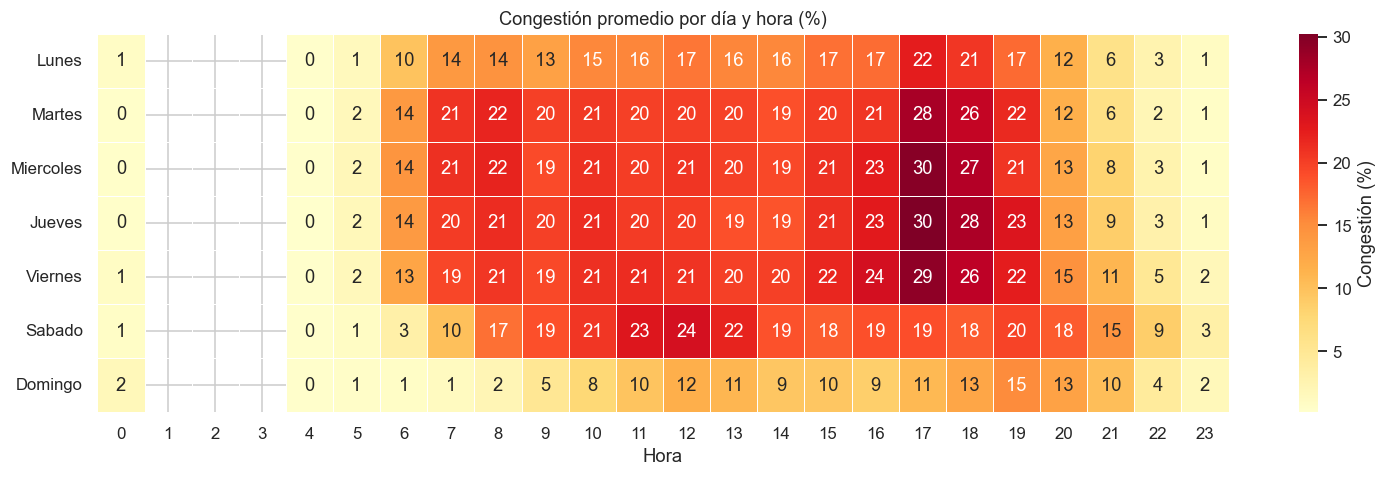

In [6]:
piv = (df.pivot_table(index="dia_semana", columns="hora", values="congestion", aggfunc="mean")
         .reindex(columns=range(24)))

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(piv * 100, cmap="YlOrRd", annot=True, fmt=".0f", linewidths=.5,
            cbar_kws={"label": "Congestión (%)"}, ax=ax)
ax.set(title="Congestión promedio por día y hora (%)", xlabel="Hora", ylabel="")
plt.tight_layout(); plt.show()

## 4. Mapa de calor: top 20 nodos × hora

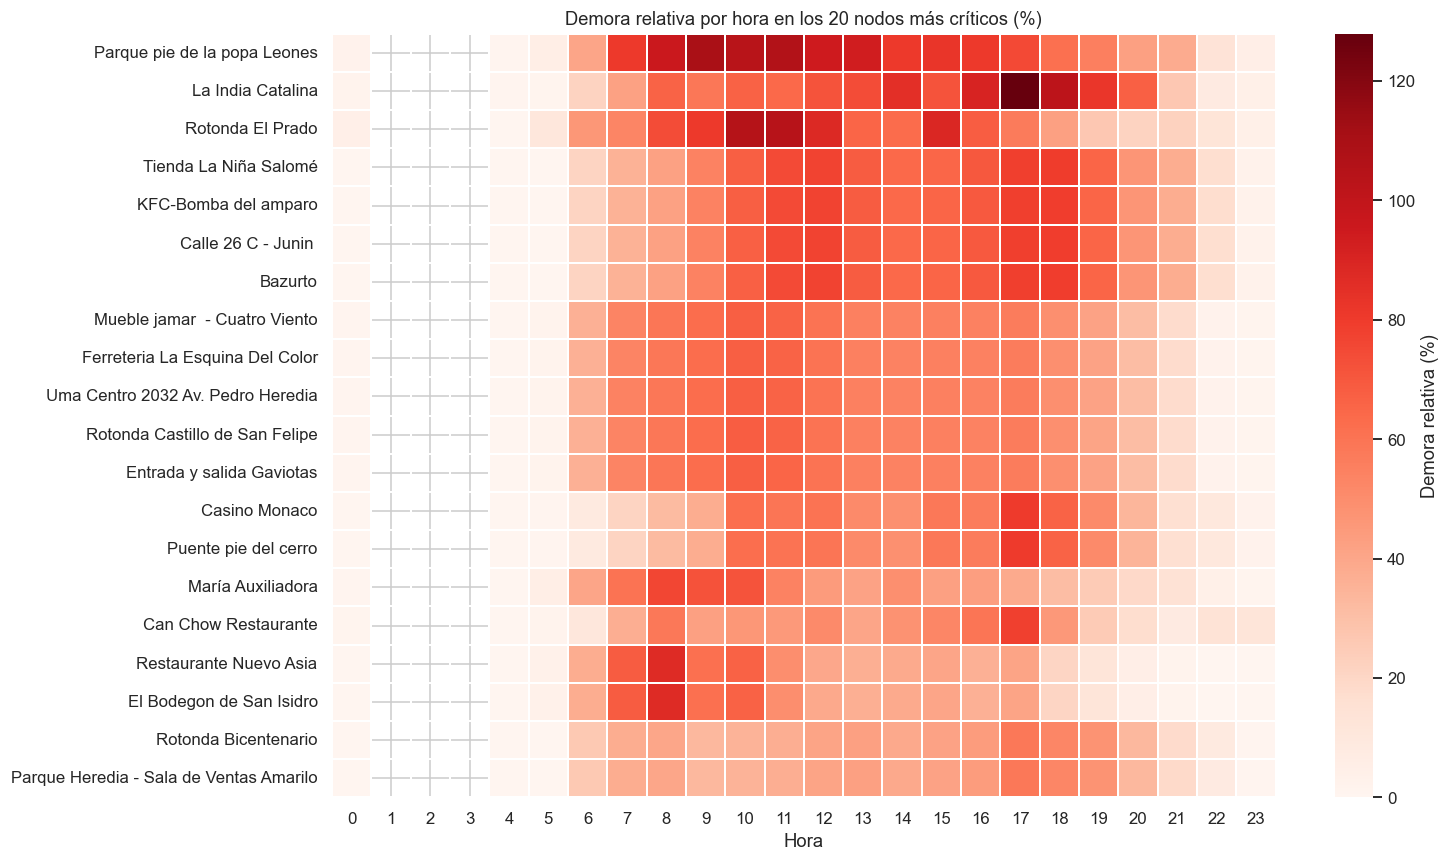

In [7]:
top20 = ranking.head(20).index
piv_n = (df[df["nombre_nodo"].isin(top20)]
         .pivot_table(index="nombre_nodo", columns="hora", values="delay_rel_pct", aggfunc="mean")
         .reindex(index=top20, columns=range(24)))

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(piv_n, cmap="Reds", linewidths=.3, cbar_kws={"label": "Demora relativa (%)"}, ax=ax)
ax.set(title="Demora relativa por hora en los 20 nodos más críticos (%)", xlabel="Hora", ylabel="")
plt.tight_layout(); plt.show()

## 5. Perfil horario: días hábiles vs fin de semana

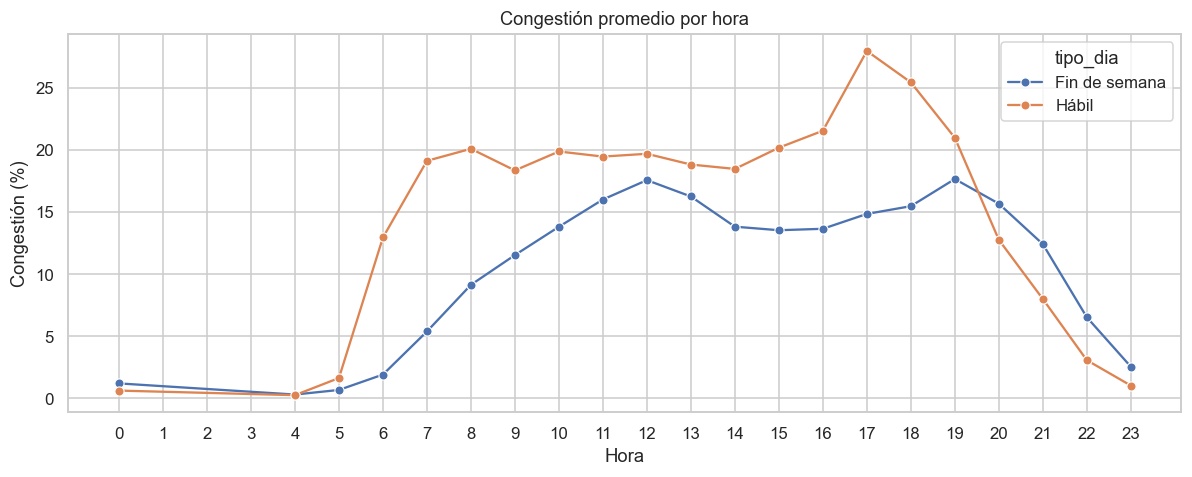

In [8]:
df["tipo_dia"] = df["dia_semana"].isin(["Sabado", "Domingo"]).map({True: "Fin de semana", False: "Hábil"})
perfil = df.groupby(["tipo_dia", "hora"])["congestion"].mean().mul(100).reset_index()

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.lineplot(data=perfil, x="hora", y="congestion", hue="tipo_dia", marker="o", ax=ax)
ax.set(title="Congestión promedio por hora", xlabel="Hora", ylabel="Congestión (%)", xticks=range(0, 24))
plt.tight_layout(); plt.show()

## 6. Cierres de vía reportados

In [9]:
cierres = (df[df["roadClosure"] == True]
           .groupby("nombre_nodo")
           .agg(mediciones_con_cierre=("roadClosure", "size"),
                primera=("consultation_time", "min"), ultima=("consultation_time", "max"))
           .sort_values("mediciones_con_cierre", ascending=False))
cierres if len(cierres) else "No hay cierres de vía reportados en el periodo." 

,mediciones_con_cierre,primera,ultima
nombre_nodo,,,
Tienda El Paisa,1236,2026-08-12 15:00:03,2026-09-30 00:00:03
Parque Piedra Bolivar,1236,2026-08-12 15:00:03,2026-09-30 00:00:03
Castellana parte de atrás,1236,2026-08-12 15:00:03,2026-09-30 00:00:03
Integral Design CM,1236,2026-08-12 15:00:03,2026-09-30 00:00:03
Centro de convenviones,213,2026-06-07 10:00:01,2026-09-27 17:00:03
Tienda el pueblo,77,2026-05-30 12:56:16,2026-09-26 22:00:03
Ara San Fernando,77,2026-05-30 12:56:16,2026-09-26 22:00:03
Oficina de la Alcaldía Menor de Cartagena,77,2026-05-30 12:56:16,2026-09-26 22:00:03
Colegio Nuestra Señora de Fatima - Ternera,70,2026-05-30 12:56:16,2026-09-26 22:00:03
